<a href="https://colab.research.google.com/github/freyebeans/ASU-assignments/blob/main/MAT422/HW3.4/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 Section 3.4 Logistic Regression
Michael Bishop

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)

## 3.4: Sigmoid/Logistic Function
The sigmoid function is defined as $\sigma(t)=\frac{1}{1+e^{-t}}$. This function can be used in logistic regression to model binary dependent variables. Additionally, the derivative of the sigmoid is $\sigma'(t)=\sigma(t)(1-\sigma(t))$, which makes it easy to use in gradient descent.

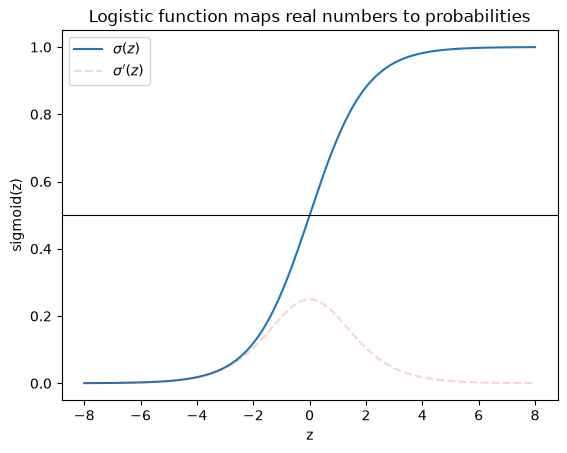

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoidp(z):
    return sigmoid(z) * (1 - sigmoid(z))

z = np.linspace(-8, 8, 300)
plt.plot(z, sigmoid(z), label="$\\sigma(z)$")
plt.axhline(0.5, color="black", linewidth=0.8)
plt.plot(z, sigmoidp(z), color="tab:red", alpha=0.2, linestyle="--", label="$\\sigma'(z)$")
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.legend()
plt.title("Logistic function maps real numbers to probabilities")
plt.show()

As you can see above the sigmoid maps from all real numbers to (0,1) making it useful for representing probabilities.
## 3.4: Binary Classification Probabilities
When classifying an object, there may be only 2 classes that object can fit in. In these cases we can represent one class as a 1 and the other as a 0. The probability of a particular object being one class or the other can be predicted using logistic regression.

In [41]:
X, y = make_classification(n_samples=130, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, class_sep=0.85, random_state=736)
model = LogisticRegression()
model.fit(X, y)
pred = model.predict(X)
proba = model.predict_proba(X)[:, 1]

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Training accuracy:", accuracy_score(y, pred))
print("Confusion matrix:")
print(confusion_matrix(y, pred))

Coefficients: [[ 3.4185 -0.8434]]
Intercept: [-0.4579]
Training accuracy: 0.9769230769230769
Confusion matrix:
[[65  1]
 [ 2 62]]


A confusion matrix represents how many object of a class are predicted to be in a particular class, along the diagonals it shows how many are correctly predicted of each class. As you can see the prediction matches closely with the real output, only predicting incorrect in 3 instances.
## 3.4: Logistic Regression Fitting and Interpretation
Provided a set of data of the form $\{(\alpha_i,b_i):i=1,\dots,n\}$ where $\alpha_i\in\real^d$ and $b_i$ is either 0 or 1, we can use logistic regression to obtain a function from $\real^d$ to (0,1) representing the probability that an input $\textbf{x}\in\real^d$ has a classification associated with 1. This is done using gradient descent to minimize $\prod_{i=1}^np(\alpha_i;\textbf{x})^{b_i}(1-p(\alpha_i;\textbf{x}))^{1-b_i}$ where $p(\alpha;\textbf{x})=\sigma(\alpha^T\textbf{x})$.

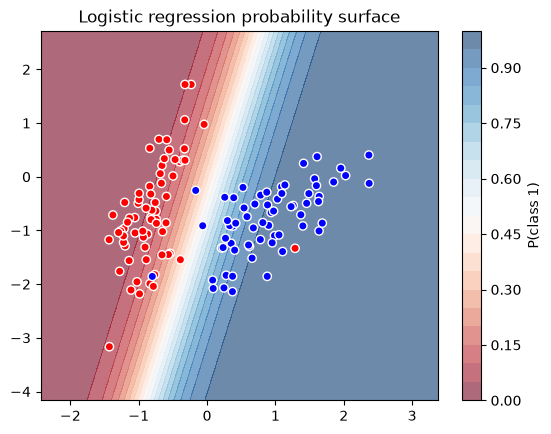

In [47]:
xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 150),
                     np.linspace(X[:,1].min()-1, X[:,1].max()+1, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(label="P(class 1)")
plt.scatter(X[:,0], X[:,1], c=1-y, edgecolor="white", cmap="bwr")
plt.title("Logistic regression probability surface")
plt.show()

As you can see, the probability of being class 1 at each $\alpha_i$ is high when $\alpha_i$ is class 1 and low when its class 0, save for a few instances, meaning logistic regression produced a function that predicts the class of an object very well.
## Reflection and Rubric Checklist
- I explained each concpet before and after the code.
- I verifed important claims numerically or visually.
- I changed and extended at least one example so that the notebook reflects my own work.
- I ran the notebook in its entirety without error.
- I saved the notebook from Google Colab directly to GitHub as per course instructions.